<a href="https://colab.research.google.com/github/Soraia-Costa/Analise-de-dados_Programaria/blob/main/Mini_projeto_%E2%80%94_Educa%C3%A7%C3%A3o_entender_padr%C3%B5es_de_participa%C3%A7%C3%A3o_e_perman%C3%AAncia_estudantil_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# pandas: leitura e manipulação de tabelas; matplotlib: visualização
import pandas as pd
import matplotlib.pyplot as plt

# Fonte principal: CSV público da UCI (dataset 697).
URL_UCI = "https://archive.ics.uci.edu/static/public/697/data.csv"

# Fonte alternativa, caso a URL principal esteja indisponível.
# Atenção: uma cópia de terceiros deve ser conferida antes de uso em produção.
URL_FALLBACK = "https://raw.githubusercontent.com/alecngo/Predict-students-dropout-and-academic-success/refs/heads/master/data.csv"

# try = tente executar; except = caso ocorra uma falha, tente a alternativa.
# Este CSV usa vírgula como separador de colunas.
try:
    dados = pd.read_csv(URL_UCI, sep=",") #ler o dado
    print("Dados carregados da fonte UCI.")
except Exception as erro:
    print(f"Fonte principal indisponível ({type(erro).__name__}). Tentando alternativa...")
    dados = pd.read_csv(URL_FALLBACK, sep=",") #lendo o dado
    print("Dados carregados da fonte alternativa. Confira a procedência.")

Dados carregados da fonte UCI.


In [2]:
dados.shape

(4424, 37)

In [4]:
dados

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


In [13]:
#colunas à ser analisadas, 1º e segundo semestre
colunas = [
    "Admission grade", #nota de admissão
    "Age at enrollment", #idade no ingresso
    "Debtor", #situação de dívida
    "Tuition fees up to date", #mensalidades em dia
    "Scholarship holder", #bolsista ou não
    "Curricular units 1st sem (enrolled)", #unidades matriculadas no 1º semestre
    "Curricular units 1st sem (approved)", #unidades aprovadas no 1º semestre
    "Curricular units 1st sem (grade)", #nota média do 1º semestre
    "Curricular units 2nd sem (enrolled)", #unidades matriculadas no 2º semestre
    "Curricular units 2nd sem (approved)", #unidades aprovadas no 2º semestre
    "Curricular units 2nd sem (grade)", #nota média do 2º semestre
    "Target" #dropout, enrolled, graduate
]


In [15]:
base = dados[colunas].copy()

In [17]:
base.head()

,Admission grade,Age at enrollment,Debtor,Tuition fees up to date,Scholarship holder,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Target
0,127.3,20,0,1,0,0,0,0.000000,0,0,0.000000,Dropout
1,142.5,19,0,0,0,6,6,14.000000,6,6,13.666667,Graduate
2,124.8,19,0,0,0,6,0,0.000000,6,0,0.000000,Dropout
3,119.6,20,0,1,0,6,6,13.428571,6,5,12.400000,Graduate
4,141.5,45,0,1,0,6,5,12.333333,6,6,13.000000,Graduate


In [21]:
#target - quem concluiu ou saiu
base["Target"].value_counts()



,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794




 -Problema: duas pessoas podem ter cinco disciplinas aprovadas, mas uma cursou cinco e a outra, dez. A contagem é igual; o aproveitamento, não.

In [24]:
# Primeiro filtramos linhas pela carga matriculada; depois limitamos a visualização.
# Este comando apenas INVESTIGA os dados; não cria nem altera colunas.
base[base["Curricular units 1st sem (enrolled)"] == 5][:20] #comparação de 5 materias

,Admission grade,Age at enrollment,Debtor,Tuition fees up to date,Scholarship holder,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Target
5,114.8,50,1,1,0,5,5,11.857143,5,5,11.500000,Graduate
7,113.1,22,0,0,0,5,0,0.000000,5,0,0.000000,Dropout
14,137.1,18,0,1,1,5,4,13.250000,5,5,12.000000,Graduate
18,136.3,20,0,1,0,5,4,12.500000,5,4,12.250000,Graduate
27,131.0,18,0,1,0,5,5,12.666667,5,4,13.000000,Enrolled
28,122.1,20,0,1,0,5,5,12.000000,5,5,12.333333,Graduate
32,138.8,18,0,0,0,5,3,11.333333,5,2,13.500000,Enrolled
34,131.4,34,0,1,0,5,5,12.400000,5,5,13.428571,Graduate
36,128.8,43,0,1,0,5,0,0.000000,5,0,0.000000,Dropout
37,122.9,55,0,1,0,5,1,10.000000,5,2,12.000000,Dropout


In [26]:
# Primeiro filtramos linhas pela carga matriculada; depois limitamos a visualização.
# Este comando apenas INVESTIGA os dados; não cria nem altera colunas.
base[base["Curricular units 1st sem (enrolled)"] == 0][:20] #comparação sem valor minino

,Admission grade,Age at enrollment,Debtor,Tuition fees up to date,Scholarship holder,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Target
0,127.3,20,0,1,0,0,0,0.0,0,0,0.0,Dropout
20,120.3,21,0,1,1,0,0,0.0,0,0,0.0,Graduate
59,115.2,18,0,1,0,0,0,0.0,0,0,0.0,Enrolled
62,126.0,19,0,1,1,0,0,0.0,0,0,0.0,Enrolled
66,128.2,19,0,1,1,0,0,0.0,0,0,0.0,Graduate
72,135.8,19,0,1,0,0,0,0.0,0,0,0.0,Dropout
101,110.0,20,0,1,0,0,0,0.0,0,0,0.0,Graduate
122,122.3,19,0,1,0,0,0,0.0,0,0,0.0,Dropout
150,121.7,18,0,1,0,0,0,0.0,0,0,0.0,Enrolled
341,178.3,18,0,1,0,0,0,0.0,0,0,0.0,Dropout


In [28]:
25/pd.NA  #Quando tiver valor 0 ou n/a posso substituir por pd para não dar erro no calculo

<NA>

In [30]:
#replace - substituir
# Sem atribuição, esta linha DEVOLVE uma Series alterada, mas não muda a coluna original.
base["Curricular units 1st sem (enrolled)"].replace(0, pd.NA)

,Curricular units 1st sem (enrolled)
0,<NA>
1,6
2,6
3,6
4,6
...,...
4419,6
4420,6
4421,7
4422,5


In [31]:
matriculadas_1 = base["Curricular units 1st sem (enrolled)"].replace(0, pd.NA)


1º Featuring -| Proporção de unidades aprovadas entre as matriculadas no 1º semestre.


In [34]:
# Exemplo: 5 aprovadas / 10 matriculadas = 0,5 (50%).
# Se não houve matrícula, o resultado será ausente, não zero.
base["taxa_aprovacao_1sem"] = (
    base["Curricular units 1st sem (approved)"] / matriculadas_1
)
# Verifique as primeiras linhas: a nova coluna foi criada?
base[["Curricular units 1st sem (enrolled)",
      "Curricular units 1st sem (approved)",
      "taxa_aprovacao_1sem"]].head()

,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),taxa_aprovacao_1sem
0,0,0,<NA>
1,6,6,1.0
2,6,0,0.0
3,6,6,1.0
4,6,5,0.833333


In [38]:

# Isso torna possível comparar semestres na mesma escala (proporção).
matriculadas_2 = base["Curricular units 2nd sem (enrolled)"].replace(0, pd.NA)

#criando a taxa de aprovação do segundo semestre
base["taxa_aprovacao_2sem"] = (
    base["Curricular units 2nd sem (approved)"] / matriculadas_2
)

# Validação rápida: taxas válidas devem estar entre 0 e 1.
# isna() ignora casos não aplicáveis à taxa.
for nome in ["taxa_aprovacao_1sem", "taxa_aprovacao_2sem"]:
    taxa_numerica = pd.to_numeric(base[nome], errors="coerce")
    print(nome, "| ausentes:", taxa_numerica.isna().sum(),
          "| fora de 0–1:", (~taxa_numerica.between(0, 1) & taxa_numerica.notna()).sum())

taxa_aprovacao_1sem | ausentes: 180 | fora de 0–1: 0
taxa_aprovacao_2sem | ausentes: 180 | fora de 0–1: 0


In [39]:
# FEATURE 2 | Diferença entre as notas médias do segundo e do primeiro semestres.
# Subtrair nessa ordem ajuda a interpretar: positivo = aumento, negativo = redução.
base["evolucao_nota"] = (
    base["Curricular units 2nd sem (grade)"]
    - base["Curricular units 1st sem (grade)"]
)

# Confira exemplos concretos para verificar o sinal da diferença.
base[["Curricular units 1st sem (grade)",
      "Curricular units 2nd sem (grade)", "evolucao_nota"]].head()

,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),evolucao_nota
0,0.000000,0.000000,0.000000
1,14.000000,13.666667,-0.333333
2,0.000000,0.000000,0.000000
3,13.428571,12.400000,-1.028571
4,12.333333,13.000000,0.666667


3º transformar uma taxa numérica em uma faixa
Nova necessidade da coordenação: comunicar o aproveitamento em categorias fáceis de comparar.


In [41]:
base["porcentagem_aprovacao_1"] = base["taxa_aprovacao_1sem"] * 100
base["porcentagem_aprovacao_1"]

,porcentagem_aprovacao_1
0,<NA>
1,100.0
2,0.0
3,100.0
4,83.333333
...,...
4419,83.333333
4420,100.0
4421,100.0
4422,100.0


In [44]:
# FEATURE 3 | Uma função que recebe UMA taxa e devolve UMA categoria.
#Vamos propor uma regra didática, criada por nós:

#-> alto: taxa a partir de 0,80;
#-> médio: taxa de 0,50 até abaixo de 0,80;
#-> baixo: taxa abaixo de 0,50;
#sem carga: taxa ausente porque não houve matrícula registrada.

def classifica_aproveitamento(taxa):
    # Começamos pelo caso ausente, evitando comparações inválidas.
    if pd.isna(taxa):
        return "sem carga"
    # A ordem importa: testamos primeiro o maior limite.
    if taxa >= 0.8:
        return "alto"
    if taxa >= 0.5:
        return "medio"
    return "baixo"  # Todos os demais valores numéricos menores que 0,5.

In [46]:
#Função para aplicar na coluna inteira -> aply()
# Teste ANTES de aplicar a função à coluna inteira.
# iloc[0] seleciona o primeiro registro pela posição, não pelo rótulo do índice.
valor_teste = base["taxa_aprovacao_1sem"].iloc[0]
print("Primeiro registro:", valor_teste, "→", classifica_aproveitamento(valor_teste))

# Testes com exemplos conhecidos, para confirmar os limites da regra.
for taxa_teste in [pd.NA, 0.30, 0.50, 0.79, 0.80, 1.00]:
    print(taxa_teste, "→", classifica_aproveitamento(taxa_teste))



Primeiro registro: <NA> → sem carga
<NA> → sem carga
0.3 → baixo
0.5 → medio
0.79 → medio
0.8 → alto
1.0 → alto


In [47]:
# .apply() chama a função UMA VEZ para cada valor da série.
# A nova coluna guarda a categoria devolvida em cada linha.
base["faixa_aproveitamento_1sem"] = (
    base["taxa_aprovacao_1sem"].apply(classifica_aproveitamento)
)

base[["taxa_aprovacao_1sem", "faixa_aproveitamento_1sem"]].head()

,taxa_aprovacao_1sem,faixa_aproveitamento_1sem
0,<NA>,sem carga
1,1.0,alto
2,0.0,baixo
3,1.0,alto
4,0.833333,alto


Conferência de qualidade: nossas categorias fizeram sentido?
Como a função transforma valores ausentes em “sem carga”, eles aparecem com esse rótulo.

In [48]:
base["faixa_aproveitamento_1sem"].value_counts(dropna=False)

,count
faixa_aproveitamento_1sem,
alto,2761
baixo,848
medio,635
sem carga,180


Usando nossas features: comparação entre grupos
Já criamos taxas, uma diferença entre notas e uma categoria. Agora chega a pergunta da coordenação:

"Os indicadores construídos aparecem de maneira diferente entre os grupos de Target?"

In [50]:
# Agrupamos por desfecho e resumimos nossas novas variáveis.
# Cada célula da tabela será uma MÉDIA, não o valor de um estudante.
resumo_target = base.groupby("Target")[[
    "taxa_aprovacao_1sem", "taxa_aprovacao_2sem", "evolucao_nota"
]].mean().round(2)

resumo_target

,taxa_aprovacao_1sem,taxa_aprovacao_2sem,evolucao_nota
Target,,,
Dropout,0.405994,0.310091,-1.36
Enrolled,0.713534,0.673128,-0.01
Graduate,0.934967,0.93207,0.05


Correlação de Pearson

A correlação de Pearson varia de −1 a +1:


*  próxima de +1: associação linear positiva;
*  próxima de −1: associação linear negativa;
*  próxima de 0: associação linear fraca ou ausente — o que não exclui relações não lineares.

Definindo se são ou nao diretamente proporcional

In [52]:
# Selecionamos variáveis NUMÉRICAS para estudar associações lineares.
variaveis_corr = [
    "Admission grade", "Age at enrollment",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "taxa_aprovacao_1sem", "taxa_aprovacao_2sem", "evolucao_nota"
]

# Float64 (com F maiúsculo) aceita valores numéricos e valores ausentes do pandas.
# Isso ajuda especialmente nas taxas em que substituímos denominadores zero.
base_corr = base[variaveis_corr].astype("Float64")

# .corr(): cada par linha × coluna mostra sua correlação linear de Pearson.
# A diagonal será 1 (variável com ela mesma), e a matriz é simétrica.
corr = base_corr.corr().round(2)
corr

,Admission grade,Age at enrollment,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),taxa_aprovacao_1sem,taxa_aprovacao_2sem,evolucao_nota
Admission grade,1.00,-0.03,0.07,0.07,0.14,0.14,0.01
Age at enrollment,-0.03,1.00,-0.16,-0.17,-0.25,-0.24,-0.05
Curricular units 1st sem (grade),0.07,-0.16,1.00,0.84,0.84,0.74,-0.17
Curricular units 2nd sem (grade),0.07,-0.17,0.84,1.00,0.80,0.86,0.40
taxa_aprovacao_1sem,0.14,-0.25,0.84,0.80,1.00,0.85,0.07
taxa_aprovacao_2sem,0.14,-0.24,0.74,0.86,0.85,1.00,0.32
evolucao_nota,0.01,-0.05,-0.17,0.40,0.07,0.32,1.00


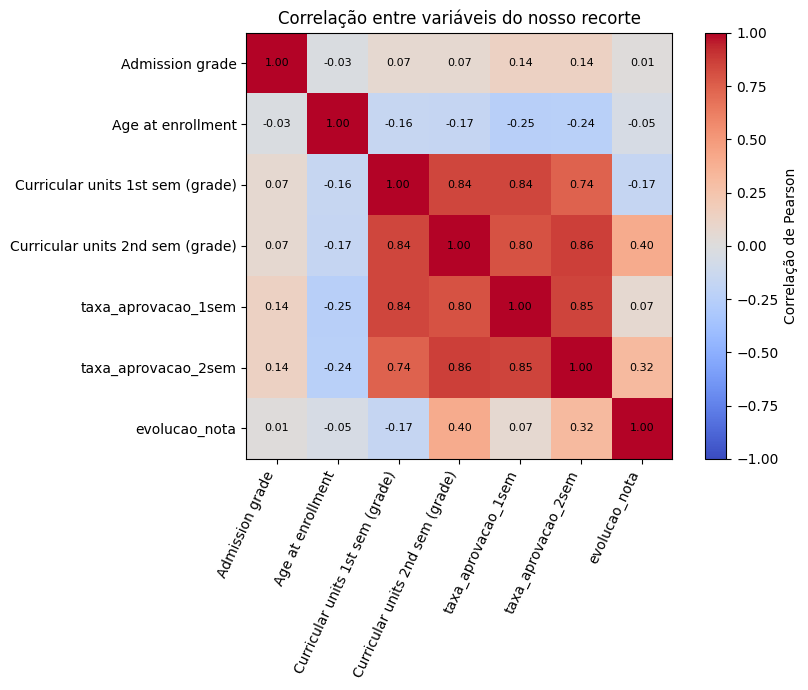

In [53]:
# Heatmap simples: mesma matriz, agora mostrada com cores.
fig, ax = plt.subplots(figsize=(9, 7))
imagem = ax.imshow(corr.astype(float), vmin=-1, vmax=1, cmap="coolwarm")

# Eixo horizontal e vertical: nomes das variáveis que estamos cruzando.
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=65, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)

# Mostramos os números para que a interpretação não dependa apenas da cor.
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        valor = corr.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}" if pd.notna(valor) else "—",
                ha="center", va="center", fontsize=8)

plt.colorbar(imagem, ax=ax, label="Correlação de Pearson")
plt.title("Correlação entre variáveis do nosso recorte")
plt.tight_layout()
plt.show()